In [33]:
!pip install -q ultralytics

In [34]:
import cv2
import os
import torch

from ultralytics import YOLO, solutions

print("OpenCV version:", cv2.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

print("Libraries imported successfully!")

OpenCV version: 4.14.0
PyTorch version: 2.11.0+cu130
CUDA available: True
Libraries imported successfully!


## Step 1: Environment Preparation

The following libraries are used in this task:

- Ultralytics: Provides pretrained YOLO models and the ObjectCounter solution.
- OpenCV: Used to read, process, and write video frames.
- PyTorch: Provides the deep learning framework required to run YOLO.

### Why OpenCV?

OpenCV is used for video processing. It allows us to read videos frame by frame, extract video information, and save the processed frames into a new video.

### Why Use a Pretrained YOLO Model?

A pretrained YOLO model has already learned to detect common objects from a large dataset. This allows us to detect objects such as people, cars, buses, and trucks without training a new model from scratch.

### What Is Object Tracking?

Object tracking means following the same detected object across consecutive video frames. Each tracked object receives an ID that helps distinguish it from other objects and avoid counting it repeatedly.

# Step 2: Load a Pretrained YOLO Model

In [35]:
model = YOLO("yolov8n.pt")

print("YOLOv8 Nano loaded successfully!")

YOLOv8 Nano loaded successfully!


In [36]:
class_names = model.names

print("Number of classes:", len(class_names))
print("\nAvailable classes:")

for class_id, class_name in class_names.items():
    print(class_id, ":", class_name)

Number of classes: 80

Available classes:
0 : person
1 : bicycle
2 : car
3 : motorcycle
4 : airplane
5 : bus
6 : train
7 : truck
8 : boat
9 : traffic light
10 : fire hydrant
11 : stop sign
12 : parking meter
13 : bench
14 : bird
15 : cat
16 : dog
17 : horse
18 : sheep
19 : cow
20 : elephant
21 : bear
22 : zebra
23 : giraffe
24 : backpack
25 : umbrella
26 : handbag
27 : tie
28 : suitcase
29 : frisbee
30 : skis
31 : snowboard
32 : sports ball
33 : kite
34 : baseball bat
35 : baseball glove
36 : skateboard
37 : surfboard
38 : tennis racket
39 : bottle
40 : wine glass
41 : cup
42 : fork
43 : knife
44 : spoon
45 : bowl
46 : banana
47 : apple
48 : sandwich
49 : orange
50 : broccoli
51 : carrot
52 : hot dog
53 : pizza
54 : donut
55 : cake
56 : chair
57 : couch
58 : potted plant
59 : bed
60 : dining table
61 : toilet
62 : tv
63 : laptop
64 : mouse
65 : remote
66 : keyboard
67 : cell phone
68 : microwave
69 : oven
70 : toaster
71 : sink
72 : refrigerator
73 : book
74 : clock
75 : vase
76 : scis

### What Is a Pretrained Model?

A pretrained model is a model that has already learned features and object patterns from a large dataset.

### Why Use COCO Pretrained Models?

COCO pretrained models can detect many common objects directly, which makes them useful for object counting without requiring a custom training process.

### Model Class Names

Model class names represent the categories that YOLO can recognize. Each category has a unique class ID used during detection and tracking.

# Step 3: Load a Traffic or Object Movement Video

In [54]:

# Load the video path
video_path = "/kaggle/input/datasets/youssefyasser74/traffic/Traffic.mp4"

# Open video using OpenCV
cap = cv2.VideoCapture(video_path)

# Check if video opened successfully
if not cap.isOpened():
    print("Error: Could not open the video")
else:
    # Extract video properties
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print("Video loaded successfully!")
    print("Width:", frame_width)
    print("Height:", frame_height)
    print("FPS:", fps)
    print("Total Frames:", total_frames)


Video loaded successfully!
Width: 1080
Height: 1920
FPS: 60.0
Total Frames: 958


FPS (Frames Per Second): Represents the number of frames displayed per second.

Frame Width and Height: Define the video resolution and are required when creating the output video.

Video Opening Check: Ensures that the video file was loaded successfully before processing it.

# Step 4: Define the Counting Line

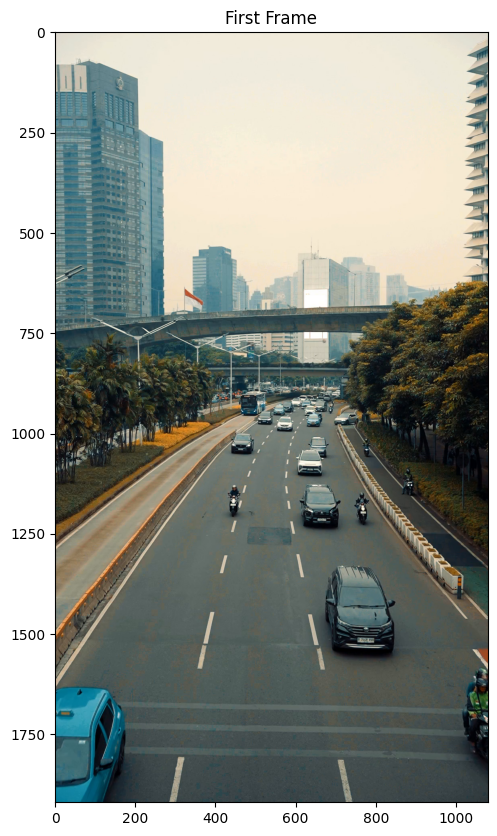

In [55]:

import matplotlib.pyplot as plt

# Read the first frame
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
ret, frame = cap.read()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 10))
    plt.imshow(frame_rgb)
    plt.title("First Frame")
    plt.axis("on")
    plt.show()
else:
    print("Error: Could not read frame")


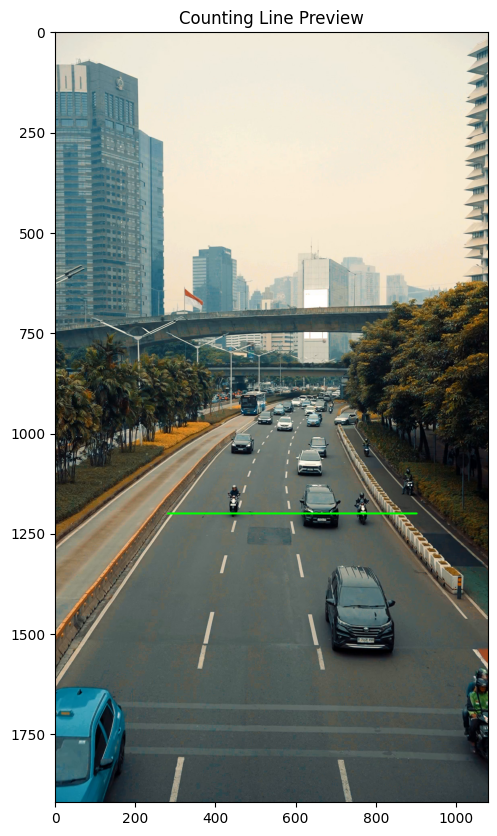

In [56]:

# Define counting line coordinates
counting_line = [(280, 1200), (900, 1200)]

# Draw the counting line on the first frame
line_frame = frame.copy()

cv2.line(
    line_frame,
    counting_line[0],
    counting_line[1],
    (0, 255, 0),
    4
)

# Display the frame
line_frame_rgb = cv2.cvtColor(line_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 10))
plt.imshow(line_frame_rgb)
plt.title("Counting Line Preview")
plt.axis("on")
plt.show()


A counting line is a virtual line placed inside the video frame to count objects when they cross it.

Line Position: The position of the line affects which objects are counted.

Clear Crossing Area: The line should be placed where objects can clearly pass through it.

Line Coordinates: The line is defined using two points (x1, y1) and (x2, y2).

# Step 5: Track and Count Objects

In [57]:

from ultralytics import YOLO, solutions
import ultralytics

# Check Ultralytics version
print("Ultralytics version:", ultralytics.__version__)

# Load pretrained YOLO nano model
model = YOLO("yolo11n.pt")

# Initialize ObjectCounter
counter = solutions.ObjectCounter(
    model="yolo11n.pt",
    region=counting_line,
    classes=[0, 1, 2, 3, 5, 7],
    show_in=True,
    show_out=True,
    verbose=False
)

print("YOLO model loaded successfully!")
print("ObjectCounter initialized successfully!")


Ultralytics version: 8.4.220
Ultralytics Solutions: ✅ {'source': None, 'model': 'yolo11n.pt', 'classes': [0, 1, 2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': [(280, 1200), (900, 1200)], 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': None, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images', 'recognizer': 'paddleocr'}
WARNING ⚠️ Environment does not support cv2.imshow() or PIL Image.show()

YOLO model loaded successfully!
ObjectCounter initialized successfully!


In [59]:

# Reset video to the first frame
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

# Output video path
output_video_path = "/kaggle/working/Traffic_counted.mp4"

# Create video writer
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

video_writer = cv2.VideoWriter(
    output_video_path,
    fourcc,
    fps,
    (frame_width, frame_height)
)

# Check video writer
if not video_writer.isOpened():
    print("Error: Could not create output video")

else:
    print("Processing video...")

    while cap.isOpened():

        # Read frame
        success, frame = cap.read()

        if not success:
            break

        # Detect, track and count objects
        results = counter(frame)

        # Write processed frame
        video_writer.write(results.plot_im)

    print("Video processing completed!")

# Release resources
cap.release()
video_writer.release()

print("Output saved at:", output_video_path)


Processing video...
Video processing completed!
Output saved at: /kaggle/working/Traffic_counted.mp4


In [60]:

# Get final counting results
print("Final Counting Results")
print("----------------------")
print("IN Count:", counter.in_count)
print("OUT Count:", counter.out_count)
print("Total Count:", counter.in_count + counter.out_count)


Final Counting Results
----------------------
IN Count: 6
OUT Count: 0
Total Count: 6


Detection: Identifies objects and their locations in each frame.

Tracking: Follows detected objects across consecutive frames.

persist=True: In manual YOLO tracking, it keeps object identities consistent between consecutive frames.

Object IDs: Assign unique IDs to tracked objects to prevent counting the same object multiple times.

ObjectCounter: Automatically handles detection, tracking, counting, and drawing the results on each frame.

# Step 6: Save the Output Video

In [63]:

# Reopen original video
cap = cv2.VideoCapture(video_path)

# Get video properties again
frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# New output path using AVI format
output_video_path = "/kaggle/working/Traffic_counted.avi"

# Initialize a new counter
counter = solutions.ObjectCounter(
    model="yolo11n.pt",
    region=counting_line,
    classes=[0, 1, 2, 3, 5, 7],
    show_in=True,
    show_out=True,
    verbose=False
)

# Create video writer
fourcc = cv2.VideoWriter_fourcc(*"MJPG")

video_writer = cv2.VideoWriter(
    output_video_path,
    fourcc,
    fps,
    (frame_width, frame_height)
)

print("Video writer opened:", video_writer.isOpened())

if not video_writer.isOpened():
    print("Error: VideoWriter could not be initialized!")

else:
    frame_count = 0

    while cap.isOpened():
        success, frame = cap.read()

        if not success:
            break

        # Process frame using YOLO ObjectCounter
        results = counter(frame)

        # Write processed frame
        video_writer.write(results.plot_im)

        frame_count += 1

    print("Processing completed!")
    print("Frames written:", frame_count)

# Release resources
cap.release()
video_writer.release()
cv2.destroyAllWindows()

print("Output path:", output_video_path)


Ultralytics Solutions: ✅ {'source': None, 'model': 'yolo11n.pt', 'classes': [0, 1, 2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': [(280, 1200), (900, 1200)], 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': None, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images', 'recognizer': 'paddleocr'}
Video writer opened: True
Processing completed!
Frames written: 958
Output path: /kaggle/working/Traffic_counted.avi


In [66]:
test_video = cv2.VideoCapture(output_video_path)

print("Video opened:", test_video.isOpened())
print("Frames:", int(test_video.get(cv2.CAP_PROP_FRAME_COUNT)))
print("File size:", os.path.getsize(output_video_path))

test_video.release()

Video opened: True
Frames: 958
File size: 262947544


In [67]:
print("Final Results")
print("IN Count:", counter.in_count)
print("OUT Count:", counter.out_count)
print("Total Count:", counter.in_count + counter.out_count)

Final Results
IN Count: 6
OUT Count: 0
Total Count: 6
